# Catching credit-card fraud — an honest model for Kaggle Playground S6E11

**Task.** Predict the probability that a card transaction is fraud (`is_fraud`). Kaggle scores submissions with ROC AUC.

**Read this first.** Playground data is **synthetic**: Kaggle generated it from a real-looking source dataset
(*Credit Card Fraud Detection 2026*). Patterns found here describe the generated data, not a real bank.

**Rules this notebook follows**
* 20% of the training data is locked away as an internal hold-out and scored **once**, at the end.
* All choices (model, features, Optuna) use 5-fold stratified cross-validation on the other 80%.
* No target encoding on full data, no statistics from the test set, `id` is never a feature.
* Every number reported anywhere in the project is written to `results/metrics.json` by this notebook.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
ON_KAGGLE = os.path.exists("/kaggle/input")
ROOT = "/kaggle/working" if ON_KAGGLE else (os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, os.path.join(ROOT, "src"))
for d_ in ["results", "figures", "models"]:
    os.makedirs(os.path.join(ROOT, d_), exist_ok=True)
from features import *
import modeling as mdl
import style
style.apply()
import matplotlib.pyplot as plt
from IPython.display import Image
R = lambda *p: os.path.join(ROOT, *p)
TRAIN = find_file("train.csv", roots=(os.path.join(ROOT, "data"),))
TEST = find_file("test.csv", roots=(os.path.join(ROOT, "data"),))
METRICS = {}
SRC = "Source: Kaggle Playground S6E11 (synthetic data, CC BY 4.0)"
print(TRAIN, TEST)

/home/claude/fraud/data/train.csv /home/claude/fraud/data/test.csv


## 1. Load and check the data

In [2]:
tr_raw, te_raw = load(TRAIN, TEST)
checks = data_checks(tr_raw, te_raw)
METRICS["data"] = checks
display(tr_raw.head(3).T)
display(pd.DataFrame({"dtype": tr_raw.dtypes.astype(str), "n_unique": tr_raw.nunique()}))
checks

,0,1,2
id,0,1,2
amount_usd,61.16,24.83,6.36
hours_since_last_txn,9.77,1.54,1.2
txn_count_last_24h,1,3,4
distance_from_home_km,17.78,13.06,8.17
card_age_months,48,38,50
customer_age,56,28,55
account_balance_usd,1269.35,3233.0,1046.88
cvv_retry_count,0,0,0
velocity_score,5.5,33.4,35.8


,dtype,n_unique
id,int64,699960
amount_usd,float64,13387
hours_since_last_txn,float64,3633
txn_count_last_24h,int64,12
distance_from_home_km,float64,4365
card_age_months,int64,49
customer_age,int64,64
account_balance_usd,float64,43317
cvv_retry_count,int64,4
velocity_score,float64,666


{'train_rows': 699960,
 'test_rows': 299984,
 'n_raw_features': 24,
 'missing_values_train': 0,
 'missing_values_test': 0,
 'duplicate_rows_train': 0,
 'train_rows_identical_to_a_test_row': 0,
 'fraud_rate_pct': 1.6699525687182124,
 'n_fraud': 11689}

**Cleaning decisions.** No missing values, no duplicate rows, and no training row identical to a test row
(see the checks above), so **no rows were removed**. The only changes: booleans → 0/1, categoricals kept as
categories (with the same levels for train and test), and four row-level features
(`red_flag_count`, `amount_to_balance`, `log_amount`, `is_night`) that use only the row itself.

In [3]:
d, cats = prepare(tr_raw)
te, _ = prepare(te_raw, categories=cats)
y_all = d[TARGET]
print(d.shape, te.shape)

(699960, 30) (299984, 29)


## 2. EDA — facts worth telling

In [4]:
def rate(col):
    g = d.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    g["mean"] *= 100
    return g

auth = rate("auth_method"); merch = rate("merchant_category"); flags = rate("red_flag_count")
flag_rates = {c: {"with_pct": float(d.loc[d[c] == 1, TARGET].mean() * 100),
                  "without_pct": float(d.loc[d[c] == 0, TARGET].mean() * 100),
                  "n_with": int((d[c] == 1).sum())} for c in BOOLEAN}
from sklearn.metrics import roc_auc_score
single_auc = {c: float(max(roc_auc_score(y_all, d[c]), 1 - roc_auc_score(y_all, d[c]))) for c in NUMERIC_RAW}
best_single = max(single_auc, key=single_auc.get)
majority_acc = float((1 - y_all.mean()) * 100)
fl3 = d["red_flag_count"] >= 3
facts = {
    "fraud_rate_pct": round(checks["fraud_rate_pct"], 2),
    "majority_class_accuracy_pct": round(majority_acc, 2),
    "no_auth_fraud_pct": round(auth.loc["No Authentication", "mean"], 2),
    "biometric_fraud_pct": round(auth.loc["Biometric", "mean"], 2),
    "no_auth_vs_biometric_x": round(auth.loc["No Authentication", "mean"] / auth.loc["Biometric", "mean"], 1),
    "ip_mismatch_fraud_pct": round(flag_rates["ip_country_mismatch"]["with_pct"], 2),
    "ip_match_fraud_pct": round(flag_rates["ip_country_mismatch"]["without_pct"], 2),
    "riskiest_category": merch["mean"].idxmax(), "riskiest_category_pct": round(merch["mean"].max(), 2),
    "safest_category": merch["mean"].idxmin(), "safest_category_pct": round(merch["mean"].min(), 2),
    "zero_flags_fraud_pct": round(flags.loc[0, "mean"], 2),
    "three_plus_flags_fraud_pct": round(float(d.loc[fl3, TARGET].mean() * 100), 2),
    "three_plus_flags_share_pct": round(float(fl3.mean() * 100), 2),
    "best_single_feature": best_single, "best_single_feature_auc": round(single_auc[best_single], 4),
    "time_of_day_auc": round(single_auc["time_of_day_hour"], 4),
    "ai_scam_flag_fraud_pct": round(flag_rates["is_ai_generated_scam_attempt"]["with_pct"], 2),
    "ai_scam_flag_n": flag_rates["is_ai_generated_scam_attempt"]["n_with"],
}
METRICS["facts"] = facts
METRICS["flag_rates"] = {k: {kk: round(vv, 3) if isinstance(vv, float) else vv for kk, vv in v.items()} for k, v in flag_rates.items()}
METRICS["single_feature_auc"] = {k: round(v, 4) for k, v in single_auc.items()}
facts

{'fraud_rate_pct': 1.67,
 'majority_class_accuracy_pct': 98.33,
 'no_auth_fraud_pct': np.float64(6.44),
 'biometric_fraud_pct': np.float64(0.5),
 'no_auth_vs_biometric_x': np.float64(12.9),
 'ip_mismatch_fraud_pct': 16.5,
 'ip_match_fraud_pct': 1.43,
 'riskiest_category': 'Gift Cards',
 'riskiest_category_pct': np.float64(7.3),
 'safest_category': 'Online Retail',
 'safest_category_pct': np.float64(1.11),
 'zero_flags_fraud_pct': np.float64(0.7),
 'three_plus_flags_fraud_pct': 54.62,
 'three_plus_flags_share_pct': 0.2,
 'best_single_feature': 'merchant_risk_score',
 'best_single_feature_auc': 0.7489,
 'time_of_day_auc': 0.5002,
 'ai_scam_flag_fraud_pct': 15.22,
 'ai_scam_flag_n': 2299}

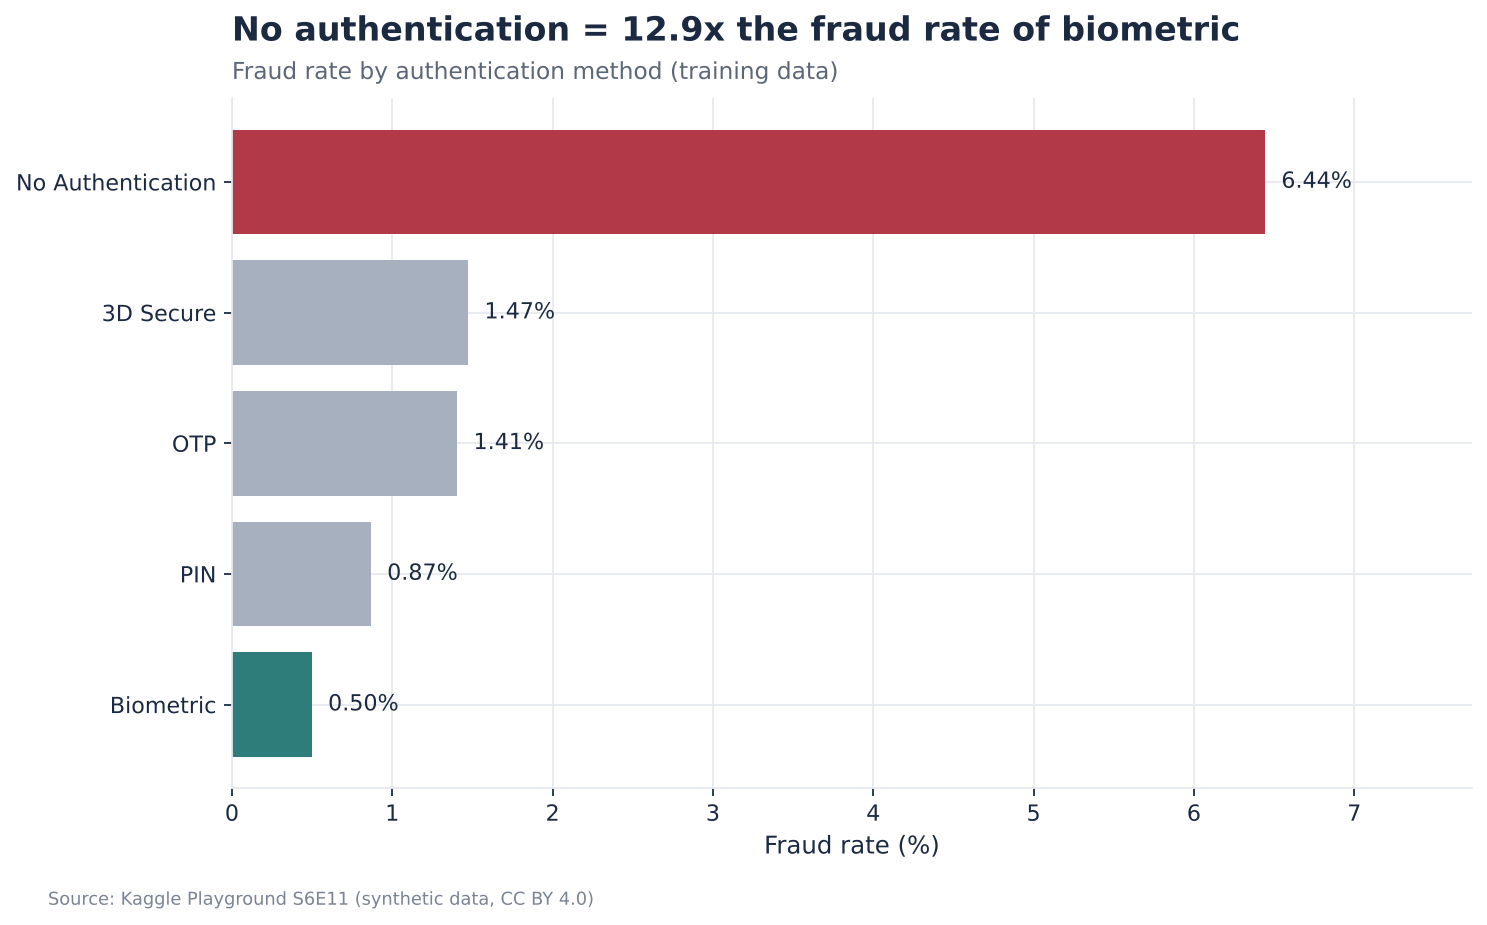

In [5]:
# Figure 1 - authentication
fig, ax = plt.subplots()
a = auth.sort_values("mean")
cols = [style.BAD if i == len(a) - 1 else (style.ACCENT_2 if i == 0 else style.MUTED) for i in range(len(a))]
ax.barh(a.index, a["mean"], color=cols)
for i, v in enumerate(a["mean"]):
    ax.text(v + 0.1, i, f"{v:.2f}%", va="center")
ax.set_xlabel("Fraud rate (%)"); ax.set_xlim(0, a["mean"].max() * 1.2)
style.title(ax, f"No authentication = {facts['no_auth_vs_biometric_x']}x the fraud rate of biometric",
            "Fraud rate by authentication method (training data)")
style.source(fig, SRC); style.save(fig, R("figures", "01_auth_method.png")); Image(R("figures", "01_auth_method.png"), width=760)

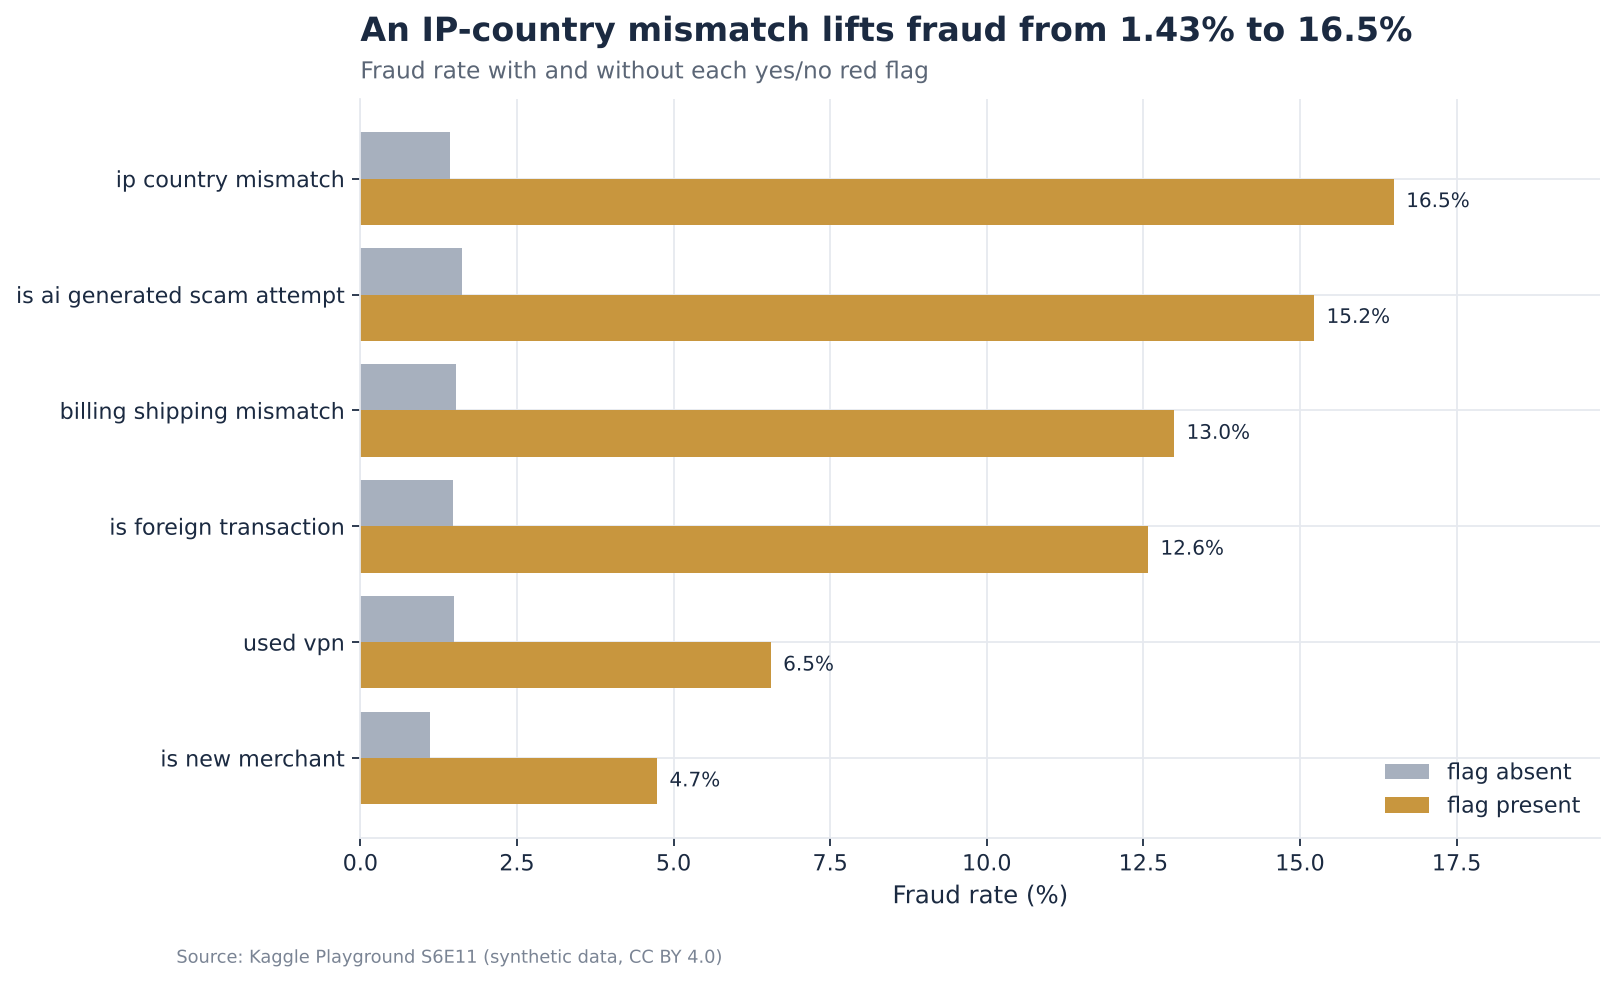

In [6]:
# Figure 2 - red flags
fig, ax = plt.subplots(figsize=(10, 6))
fr = pd.DataFrame(flag_rates).T.sort_values("with_pct")
yy = np.arange(len(fr))
ax.barh(yy + 0.2, fr["without_pct"], height=0.4, color=style.MUTED, label="flag absent")
ax.barh(yy - 0.2, fr["with_pct"], height=0.4, color=style.ACCENT, label="flag present")
for i, (w, wo) in enumerate(zip(fr["with_pct"], fr["without_pct"])):
    ax.text(w + 0.2, i - 0.2, f"{w:.1f}%", va="center", fontsize=9)
ax.set_yticks(yy); ax.set_yticklabels([c.replace("_", " ") for c in fr.index])
ax.set_xlabel("Fraud rate (%)"); ax.set_xlim(0, fr["with_pct"].max() * 1.2); ax.legend(loc="lower right")
style.title(ax, f"An IP-country mismatch lifts fraud from {facts['ip_match_fraud_pct']}% to {facts['ip_mismatch_fraud_pct']}%",
            "Fraud rate with and without each yes/no red flag")
style.source(fig, SRC); style.save(fig, R("figures", "02_red_flags.png")); Image(R("figures", "02_red_flags.png"), width=760)

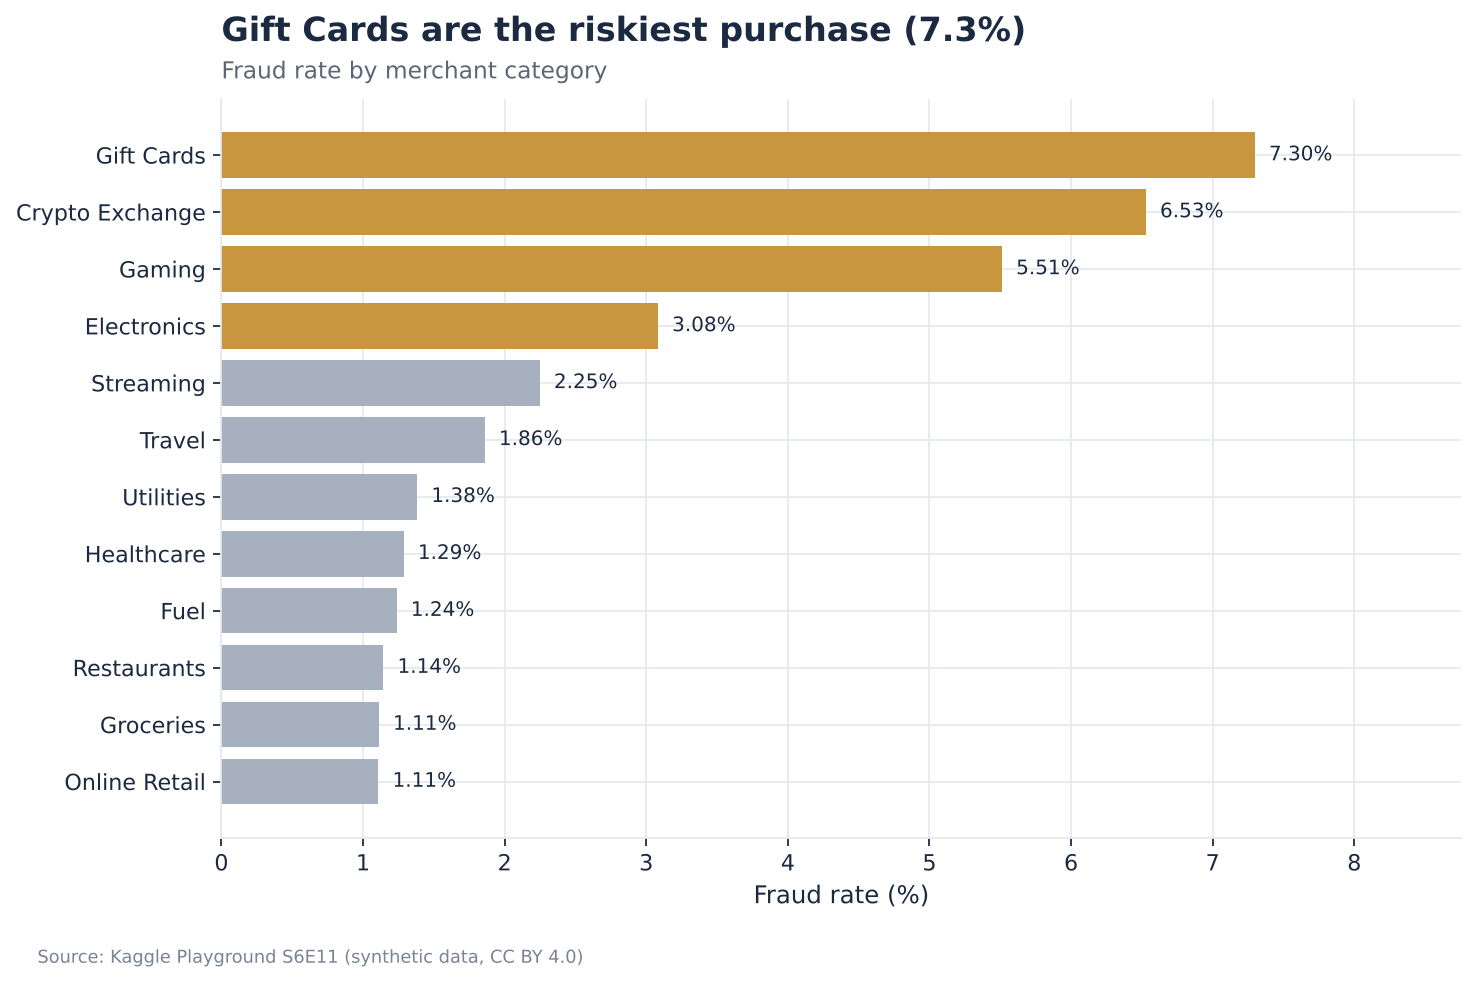

In [7]:
# Figure 3 - merchant category
fig, ax = plt.subplots(figsize=(10, 6))
m_ = merch.sort_values("mean")
ax.barh(m_.index, m_["mean"], color=[style.ACCENT if v > 3 else style.MUTED for v in m_["mean"]])
for i, v in enumerate(m_["mean"]):
    ax.text(v + 0.1, i, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlabel("Fraud rate (%)"); ax.set_xlim(0, m_["mean"].max() * 1.2)
style.title(ax, f"{facts['riskiest_category']} are the riskiest purchase ({facts['riskiest_category_pct']}%)",
            "Fraud rate by merchant category")
style.source(fig, SRC); style.save(fig, R("figures", "03_merchant_category.png")); Image(R("figures", "03_merchant_category.png"), width=760)

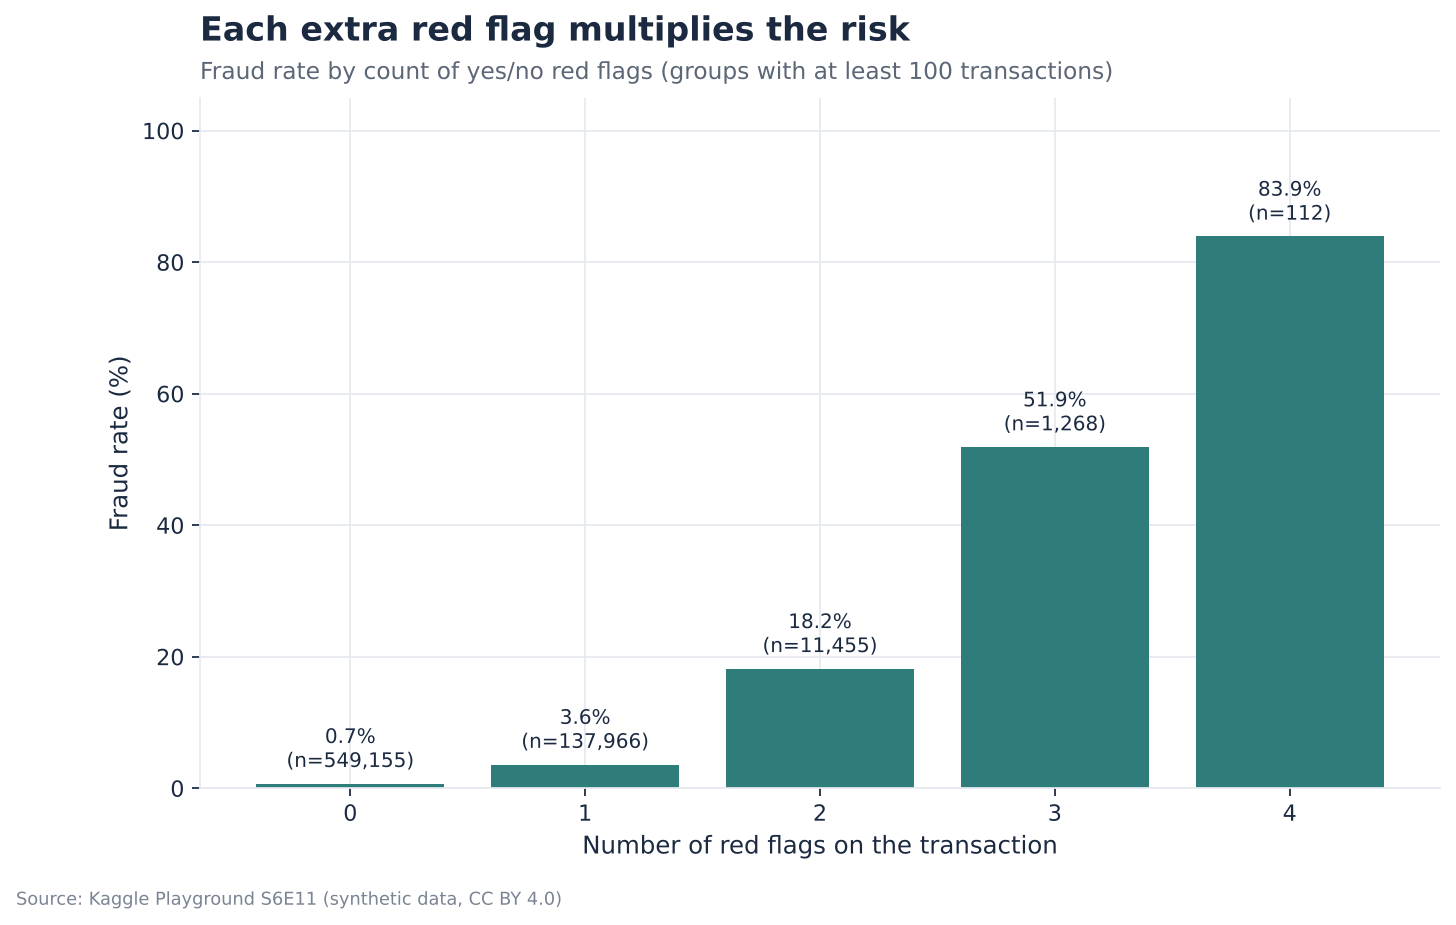

In [8]:
# Figure 4 - number of red flags
fig, ax = plt.subplots()
f_ = flags[flags["size"] >= 100]
ax.bar(f_.index.astype(int).astype(str), f_["mean"], color=style.ACCENT_2)
for i, (v, n) in enumerate(zip(f_["mean"], f_["size"])):
    ax.text(i, v + 1.5, f"{v:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Number of red flags on the transaction"); ax.set_ylabel("Fraud rate (%)")
ax.set_ylim(0, f_["mean"].max() * 1.25)
style.title(ax, "Each extra red flag multiplies the risk",
            "Fraud rate by count of yes/no red flags (groups with at least 100 transactions)")
style.source(fig, SRC); style.save(fig, R("figures", "04_flag_count.png")); Image(R("figures", "04_flag_count.png"), width=760)

## 3. Validation design

* **Target:** `is_fraud` (1.67% positives).
* **Why not a time split?** The data has no date or ordering column, so there is no "future" to protect.
  Stratified K-fold is the right tool here; a time split would be invented.
* **Internal hold-out:** 20% stratified, locked until the end. **Model selection:** 5-fold stratified CV on the other 80%.
* **Metrics:** ROC AUC (Kaggle's metric), PR AUC (better for rare classes), and a business view:
  *if analysts review the riskiest 1% of transactions, what share of all fraud do they catch, and how many of the
  reviewed cases are really fraud?*

In [9]:
dev, hold = mdl.holdout_split(d)
fl = mdl.folds(dev[TARGET].to_numpy())
assert set(dev.index).isdisjoint(hold.index)
METRICS["splits"] = {"dev_rows": int(len(dev)), "holdout_rows": int(len(hold)), "n_folds": mdl.N_FOLDS,
                     "dev_fraud_pct": round(float(dev[TARGET].mean() * 100), 3),
                     "holdout_fraud_pct": round(float(hold[TARGET].mean() * 100), 3),
                     "n_features": len(FEATURES)}
assert ID not in FEATURES and TARGET not in FEATURES
METRICS["splits"]

{'dev_rows': 559968,
 'holdout_rows': 139992,
 'n_folds': 5,
 'dev_fraud_pct': 1.67,
 'holdout_fraud_pct': 1.67,
 'n_features': 28}

## 4. Baselines and models (5-fold CV on the development set)

In [10]:
yd = dev[TARGET].to_numpy()
oofs, timings, iters = {}, {}, {}
oofs["Always 'not fraud'"] = mdl.baseline_majority(dev)
oofs["One feature (merchant risk score)"] = mdl.baseline_one_feature(dev)
oofs["Red-flag rule"] = mdl.baseline_rule(dev)
for name, kind in [("Logistic Regression", "logreg"), ("Random Forest", "rf"), ("XGBoost", "xgb"), ("LightGBM", "lgbm")]:
    (o, it), timings[name] = mdl.timed(mdl.cv_oof, dev, kind, fl)
    oofs[name] = o; iters[name] = it
cv_table = pd.DataFrame({k: mdl.metrics(yd, v) for k, v in oofs.items()}).T
cv_table.loc["Always 'not fraud'", "accuracy_at_0.5"] = mdl.accuracy_at_05(yd, oofs["Always 'not fraud'"])
for k in ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]:
    cv_table.loc[k, "accuracy_at_0.5"] = mdl.accuracy_at_05(yd, oofs[k])
cv_table = cv_table.sort_values("roc_auc", ascending=False)
display(cv_table.round(4)); print(timings)

,roc_auc,pr_auc,recall_at_top1pct,precision_at_top1pct,brier,log_loss,n,accuracy_at_0.5
XGBoost,0.9466,0.5033,38.5627,64.3929,0.0111,0.0458,559968.0,98.6640
LightGBM,0.9463,0.5017,38.5306,64.3393,0.0111,0.0460,559968.0,98.6714
Logistic Regression,0.9423,0.4874,37.4185,62.4821,0.0113,0.0471,559968.0,98.6464
Random Forest,0.9263,0.4256,34.1247,56.9821,0.0122,0.0516,559968.0,98.5392
Red-flag rule,0.8386,0.1963,20.1690,33.6786,0.9814,13.5583,559968.0,NaN
One feature (merchant risk score),0.7497,0.0533,7.1757,11.9821,0.9809,13.5514,559968.0,NaN
Always 'not fraud',0.5000,0.0167,0.8769,1.4643,0.0167,0.2307,559968.0,98.3301


{'Logistic Regression': 17.7, 'Random Forest': 387.8, 'XGBoost': 117.1, 'LightGBM': 91.8}


## 5. Tune the best family with Optuna (3-fold CV inside the development set)

In [11]:
ml = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]
best_family = cv_table.loc[ml, "roc_auc"].idxmax()
print("best family on CV:", best_family)
N_TRIALS = 20
study = mdl.tune_lgbm(dev, n_trials=N_TRIALS)
best = dict(study.best_params)
print(best, round(study.best_value, 5))
(o, it), timings["LightGBM (tuned)"] = mdl.timed(mdl.cv_oof, dev, "lgbm", fl, learning_rate=0.05, **best)
oofs["LightGBM (tuned)"] = o; iters["LightGBM (tuned)"] = it
# simple blend candidate: average of ranks of the two best different families
from scipy.stats import rankdata
blend = (rankdata(oofs["LightGBM (tuned)"]) + rankdata(oofs["Logistic Regression"])) / (2 * len(yd))
oofs["Blend: tuned LightGBM + LogReg (rank avg)"] = blend
cv_table = pd.DataFrame({k: mdl.metrics(yd, v) for k, v in oofs.items()}).T.sort_values("roc_auc", ascending=False)
for k in ml + ["LightGBM (tuned)", "Always 'not fraud'"]:
    cv_table.loc[k, "accuracy_at_0.5"] = mdl.accuracy_at_05(yd, oofs[k])
display(cv_table.round(4))
METRICS["cv"] = {k: {kk: (round(float(vv), 5) if pd.notna(vv) else None) for kk, vv in v.items()} for k, v in cv_table.to_dict("index").items()}
METRICS["tuning"] = {"family": "LightGBM", "n_trials": N_TRIALS, "tuning_folds": 3, "tuning_learning_rate": 0.1,
                     "best_params": {k: (round(v, 6) if isinstance(v, float) else v) for k, v in best.items()},
                     "cv_auc_untuned": round(float(METRICS["cv"]["LightGBM"]["roc_auc"]), 5),
                     "cv_auc_tuned": round(float(METRICS["cv"]["LightGBM (tuned)"]["roc_auc"]), 5),
                     "mean_best_iteration": round(float(np.mean(iters["LightGBM (tuned)"])), 1)}
candidates = ["LightGBM (tuned)", "Blend: tuned LightGBM + LogReg (rank avg)"]
chosen = max(candidates, key=lambda k: METRICS["cv"][k]["roc_auc"])
METRICS["chosen_model"] = chosen
print("chosen on CV:", chosen)

best family on CV: XGBoost


{'num_leaves': 9, 'min_child_samples': 708, 'colsample_bytree': 0.35461250494132657, 'subsample': 0.8185802687348942, 'reg_lambda': 0.7981086451672406, 'min_split_gain': 0.4034507147791867} 0.94704


,roc_auc,pr_auc,recall_at_top1pct,precision_at_top1pct,brier,log_loss,n,accuracy_at_0.5
LightGBM (tuned),0.9472,0.5094,38.7766,64.7500,0.0110,0.0455,559968.0,98.6714
XGBoost,0.9466,0.5033,38.5627,64.3929,0.0111,0.0458,559968.0,98.6640
LightGBM,0.9463,0.5017,38.5306,64.3393,0.0111,0.0460,559968.0,98.6714
Blend: tuned LightGBM + LogReg (rank avg),0.9462,0.5065,38.4451,64.1964,0.3162,0.9244,559968.0,NaN
Logistic Regression,0.9423,0.4874,37.4185,62.4821,0.0113,0.0471,559968.0,98.6464
Random Forest,0.9263,0.4256,34.1247,56.9821,0.0122,0.0516,559968.0,98.5392
Red-flag rule,0.8386,0.1963,20.1690,33.6786,0.9814,13.5583,559968.0,NaN
One feature (merchant risk score),0.7497,0.0533,7.1757,11.9821,0.9809,13.5514,559968.0,NaN
Always 'not fraud',0.5000,0.0167,0.8769,1.4643,0.0167,0.2307,559968.0,98.3301


chosen on CV: LightGBM (tuned)


## 6. The locked hold-out (scored once)

In [12]:
n_iter = int(round(np.mean(iters["LightGBM (tuned)"]) * 1.1))
final_lgbm = mdl.fit_lgbm(mdl.X_tree(dev), dev[TARGET], learning_rate=0.05, n_estimators=n_iter, **best)
p_lgbm = final_lgbm.predict_proba(mdl.X_tree(hold))[:, 1]
final_lr = mdl.make_logreg().fit(dev[FEATURES], dev[TARGET])
p_lr = final_lr.predict_proba(hold[FEATURES])[:, 1]
p_blend = (rankdata(p_lgbm) + rankdata(p_lr)) / (2 * len(p_lgbm))
yh = hold[TARGET].to_numpy()
hold_preds = {"Always 'not fraud'": mdl.baseline_majority(hold), "One feature (merchant risk score)": mdl.baseline_one_feature(hold),
              "Red-flag rule": mdl.baseline_rule(hold), "Logistic Regression": p_lr, "LightGBM (tuned)": p_lgbm,
              "Blend: tuned LightGBM + LogReg (rank avg)": p_blend}
hold_table = pd.DataFrame({k: mdl.metrics(yh, v) for k, v in hold_preds.items()}).T.sort_values("roc_auc", ascending=False)
for k in ["Always 'not fraud'", "Logistic Regression", "LightGBM (tuned)"]:
    hold_table.loc[k, "accuracy_at_0.5"] = mdl.accuracy_at_05(yh, hold_preds[k])
display(hold_table.round(4))
METRICS["holdout"] = {k: {kk: (round(float(vv), 5) if pd.notna(vv) else None) for kk, vv in v.items()} for k, v in hold_table.to_dict("index").items()}
ch = METRICS["holdout"][chosen]; rule = METRICS["holdout"]["Red-flag rule"]; one = METRICS["holdout"]["One feature (merchant risk score)"]
METRICS["headline"] = {"chosen_model": chosen, "holdout_auc": ch["roc_auc"], "holdout_pr_auc": ch["pr_auc"],
    "holdout_recall_top1pct": ch["recall_at_top1pct"], "holdout_precision_top1pct": ch["precision_at_top1pct"],
    "rule_holdout_auc": rule["roc_auc"], "rule_recall_top1pct": rule["recall_at_top1pct"],
    "one_feature_holdout_auc": one["roc_auc"], "cv_auc_chosen": METRICS["cv"][chosen]["roc_auc"],
    "lgbm_holdout_accuracy_at_05": METRICS["holdout"]["LightGBM (tuned)"]["accuracy_at_0.5"],
    "majority_holdout_accuracy": METRICS["holdout"]["Always 'not fraud'"]["accuracy_at_0.5"],
    "lift_top1pct_x": round(ch["precision_at_top1pct"] / (yh.mean() * 100), 1),
    "logreg_holdout_auc": METRICS["holdout"]["Logistic Regression"]["roc_auc"],
    "lgbm_holdout_auc": METRICS["holdout"]["LightGBM (tuned)"]["roc_auc"]}
METRICS["headline"]

,roc_auc,pr_auc,recall_at_top1pct,precision_at_top1pct,brier,log_loss,n,accuracy_at_0.5
LightGBM (tuned),0.9460,0.5202,39.1788,65.4286,0.0109,0.0455,139992.0,98.7014
Blend: tuned LightGBM + LogReg (rank avg),0.9448,0.5168,39.3926,65.7857,0.3162,0.9243,139992.0,NaN
Logistic Regression,0.9405,0.4971,38.4089,64.1429,0.0112,0.0471,139992.0,98.6814
Red-flag rule,0.8471,0.2101,21.2147,35.4286,0.9814,13.5588,139992.0,NaN
One feature (merchant risk score),0.7457,0.0506,6.2019,10.3571,0.9810,13.5528,139992.0,NaN
Always 'not fraud',0.5000,0.0167,0.8554,1.4286,0.0167,0.2307,139992.0,98.3299


{'chosen_model': 'LightGBM (tuned)',
 'holdout_auc': 0.94601,
 'holdout_pr_auc': 0.52019,
 'holdout_recall_top1pct': 39.17879,
 'holdout_precision_top1pct': 65.42857,
 'rule_holdout_auc': 0.84711,
 'rule_recall_top1pct': 21.21471,
 'one_feature_holdout_auc': 0.74573,
 'cv_auc_chosen': 0.94719,
 'lgbm_holdout_accuracy_at_05': 98.70135,
 'majority_holdout_accuracy': 98.3299,
 'lift_top1pct_x': np.float64(39.2),
 'logreg_holdout_auc': 0.94048,
 'lgbm_holdout_auc': 0.94601}

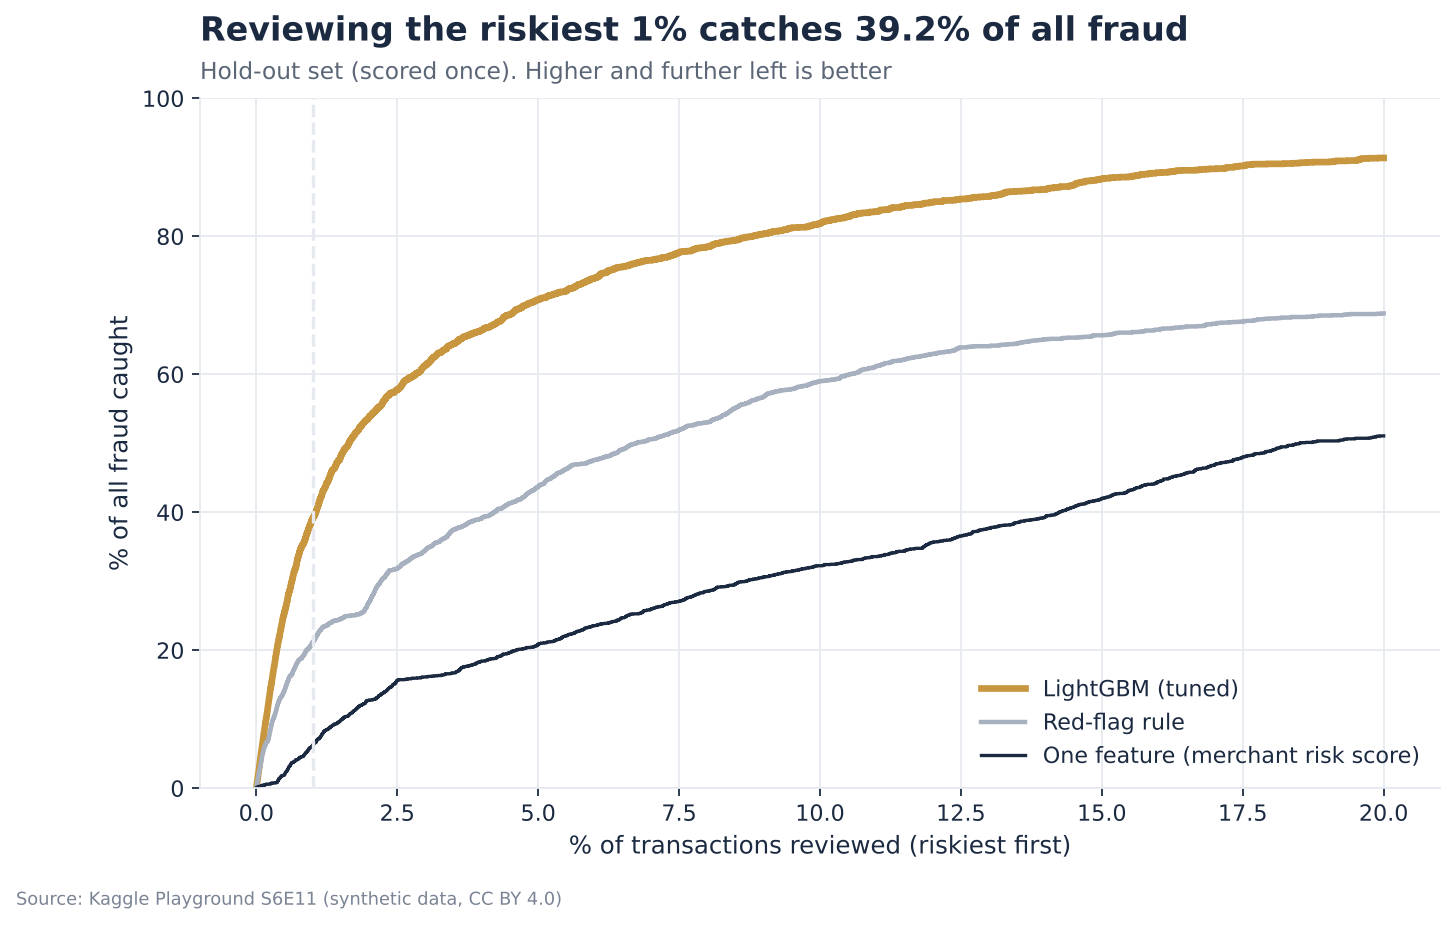

In [13]:
# gain curve: share of all fraud caught vs share of transactions reviewed
def gain(y, p):
    o = np.argsort(-p, kind="mergesort"); c = np.cumsum(y[o]) / y.sum()
    x = np.arange(1, len(y) + 1) / len(y)
    return x, c
review = [0.005, 0.01, 0.02, 0.05, 0.10]
gains = {}
for name in [chosen, "Red-flag rule", "One feature (merchant risk score)"]:
    x, c = gain(yh, hold_preds[name])
    gains[name] = {f"{int(r*1000)/10}%": round(float(c[int(len(c) * r) - 1] * 100), 2) for r in review}
METRICS["gain_holdout"] = gains
fig, ax = plt.subplots()
for name, col, lw in [(chosen, style.ACCENT, 3), ("Red-flag rule", style.MUTED, 2), ("One feature (merchant risk score)", style.INK, 1.5)]:
    x, c = gain(yh, hold_preds[name])
    ax.plot(x[: int(len(x) * 0.2)] * 100, c[: int(len(x) * 0.2)] * 100, color=col, lw=lw, label=name)
ax.axvline(1, color=style.GRID, ls="--")
ax.set_xlabel("% of transactions reviewed (riskiest first)"); ax.set_ylabel("% of all fraud caught"); ax.set_ylim(0, 100)
ax.legend(loc="lower right")
g1 = gains[chosen]["1.0%"]
style.title(ax, f"Reviewing the riskiest 1% catches {g1:.1f}% of all fraud",
            "Hold-out set (scored once). Higher and further left is better")
style.source(fig, SRC); style.save(fig, R("figures", "05_gain_curve.png")); Image(R("figures", "05_gain_curve.png"), width=760)

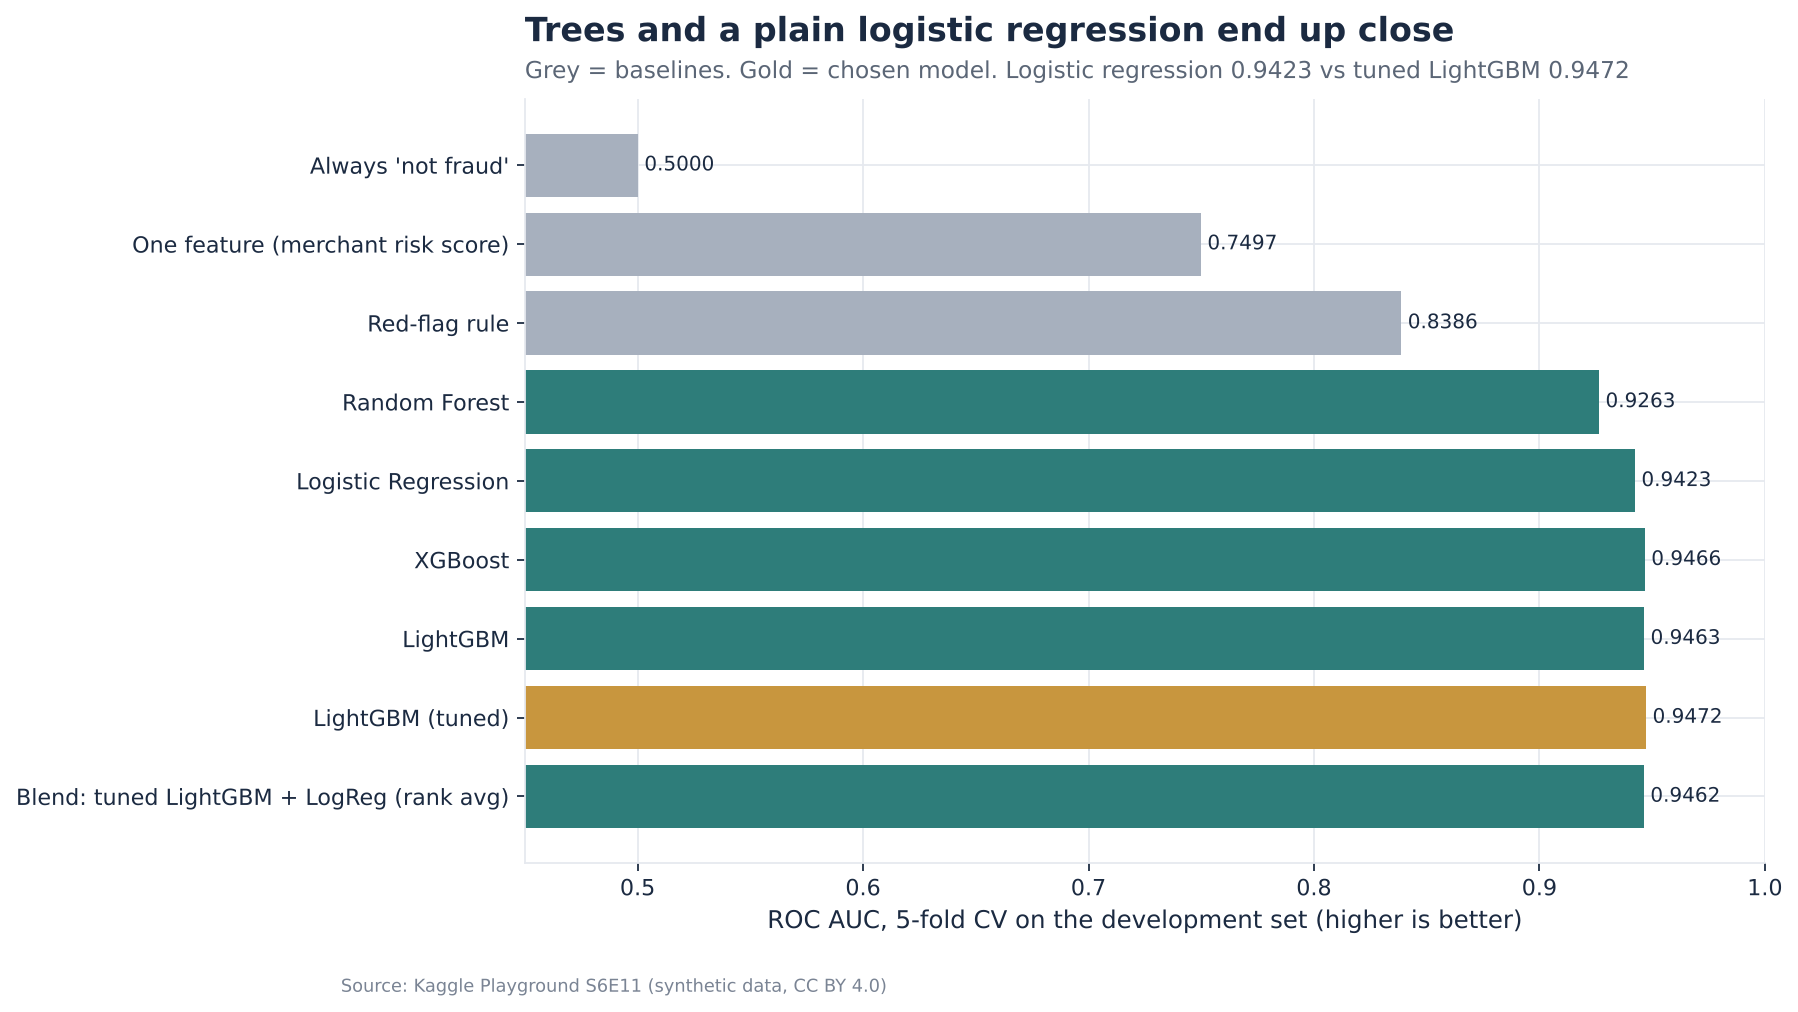

In [14]:
# Figure 6 - model comparison (CV)
order = ["Always 'not fraud'", "One feature (merchant risk score)", "Red-flag rule", "Random Forest", "Logistic Regression",
         "XGBoost", "LightGBM", "LightGBM (tuned)", "Blend: tuned LightGBM + LogReg (rank avg)"]
vals = [METRICS["cv"][o]["roc_auc"] for o in order]
fig, ax = plt.subplots(figsize=(10, 6.2))
cols = [style.MUTED if i < 3 else style.ACCENT_2 for i in range(len(order))]
cols[order.index(chosen)] = style.ACCENT
ax.barh(order[::-1], vals[::-1], color=cols[::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0.45, 1.0); ax.set_xlabel("ROC AUC, 5-fold CV on the development set (higher is better)")
style.title(ax, "Trees and a plain logistic regression end up close",
            f"Grey = baselines. Gold = chosen model. Logistic regression {METRICS['cv']['Logistic Regression']['roc_auc']:.4f} vs tuned LightGBM {METRICS['cv']['LightGBM (tuned)']['roc_auc']:.4f}")
style.source(fig, SRC); style.save(fig, R("figures", "06_model_comparison.png")); Image(R("figures", "06_model_comparison.png"), width=760)

## 7. Calibration — can the probabilities be trusted?

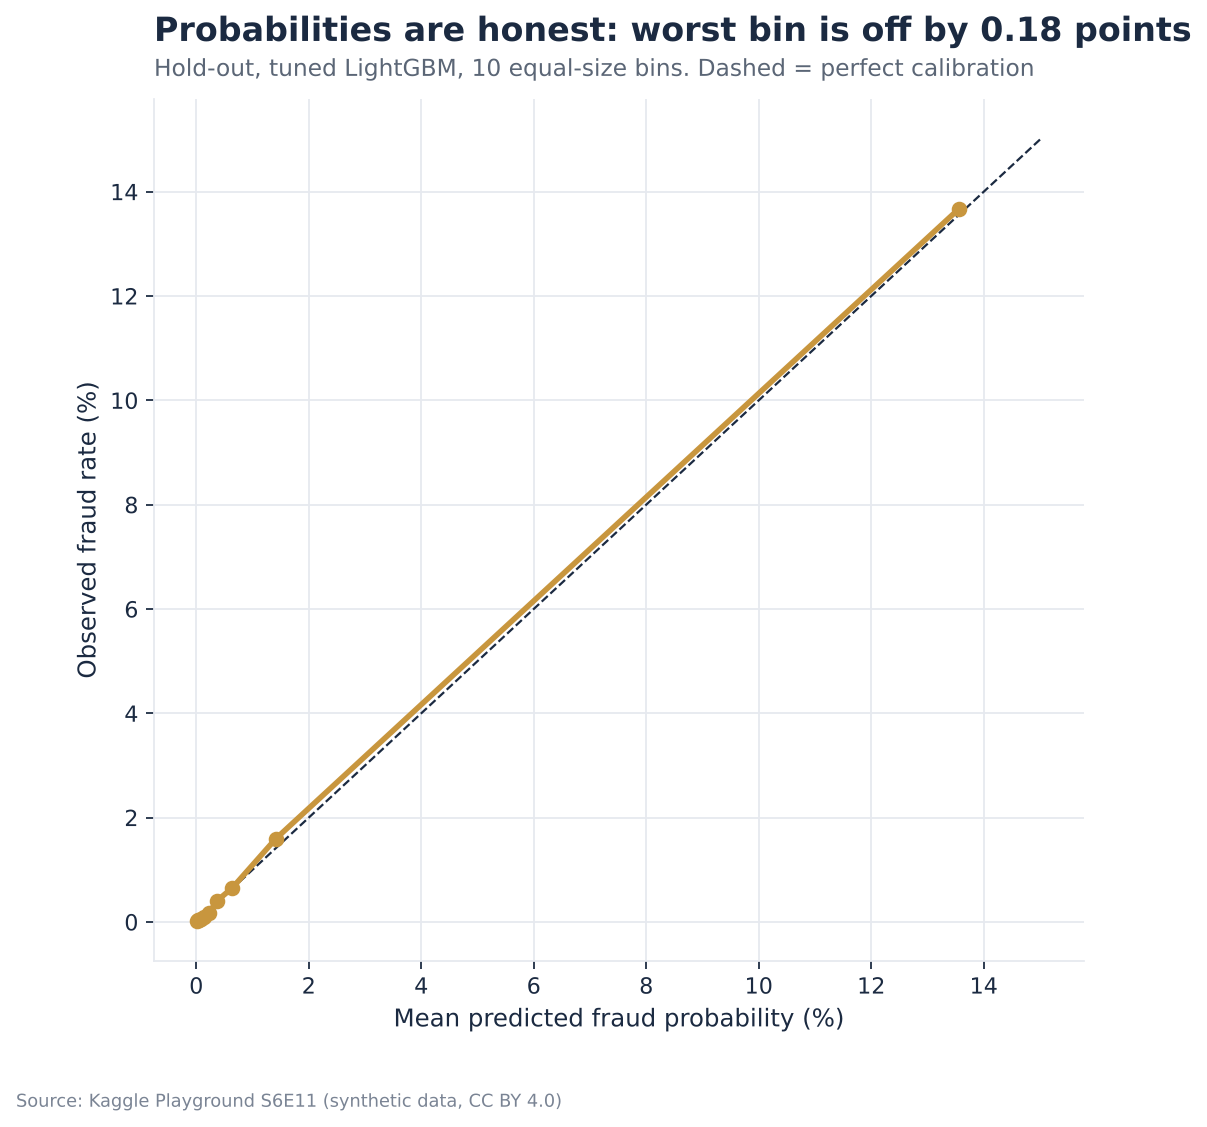

In [15]:
rel = mdl.reliability(yh, p_lgbm, n_bins=10)
METRICS["calibration_lgbm_holdout"] = {"brier": METRICS["holdout"]["LightGBM (tuned)"]["brier"],
    "brier_constant_rate": round(float(np.mean((yh - yh.mean()) ** 2)), 5),
    "top_bin_mean_pred_pct": round(float(rel["mean_pred"].iloc[-1] * 100), 2),
    "top_bin_observed_pct": round(float(rel["frac_pos"].iloc[-1] * 100), 2),
    "max_abs_gap_pct_points": round(float((rel["mean_pred"] - rel["frac_pos"]).abs().max() * 100), 2)}
fig, ax = plt.subplots(figsize=(7.5, 7))
lim = max(rel["mean_pred"].max(), rel["frac_pos"].max()) * 100 * 1.1
ax.plot([0, lim], [0, lim], ls="--", color=style.INK, lw=1)
ax.plot(rel["mean_pred"] * 100, rel["frac_pos"] * 100, marker="o", color=style.ACCENT, lw=2.5)
ax.set_xlabel("Mean predicted fraud probability (%)"); ax.set_ylabel("Observed fraud rate (%)")
cal = METRICS["calibration_lgbm_holdout"]
style.title(ax, f"Probabilities are honest: worst bin is off by {cal['max_abs_gap_pct_points']} points",
            "Hold-out, tuned LightGBM, 10 equal-size bins. Dashed = perfect calibration")
style.source(fig, SRC); style.save(fig, R("figures", "07_calibration.png")); Image(R("figures", "07_calibration.png"), width=600)

## 8. Explanation — SHAP and real cases

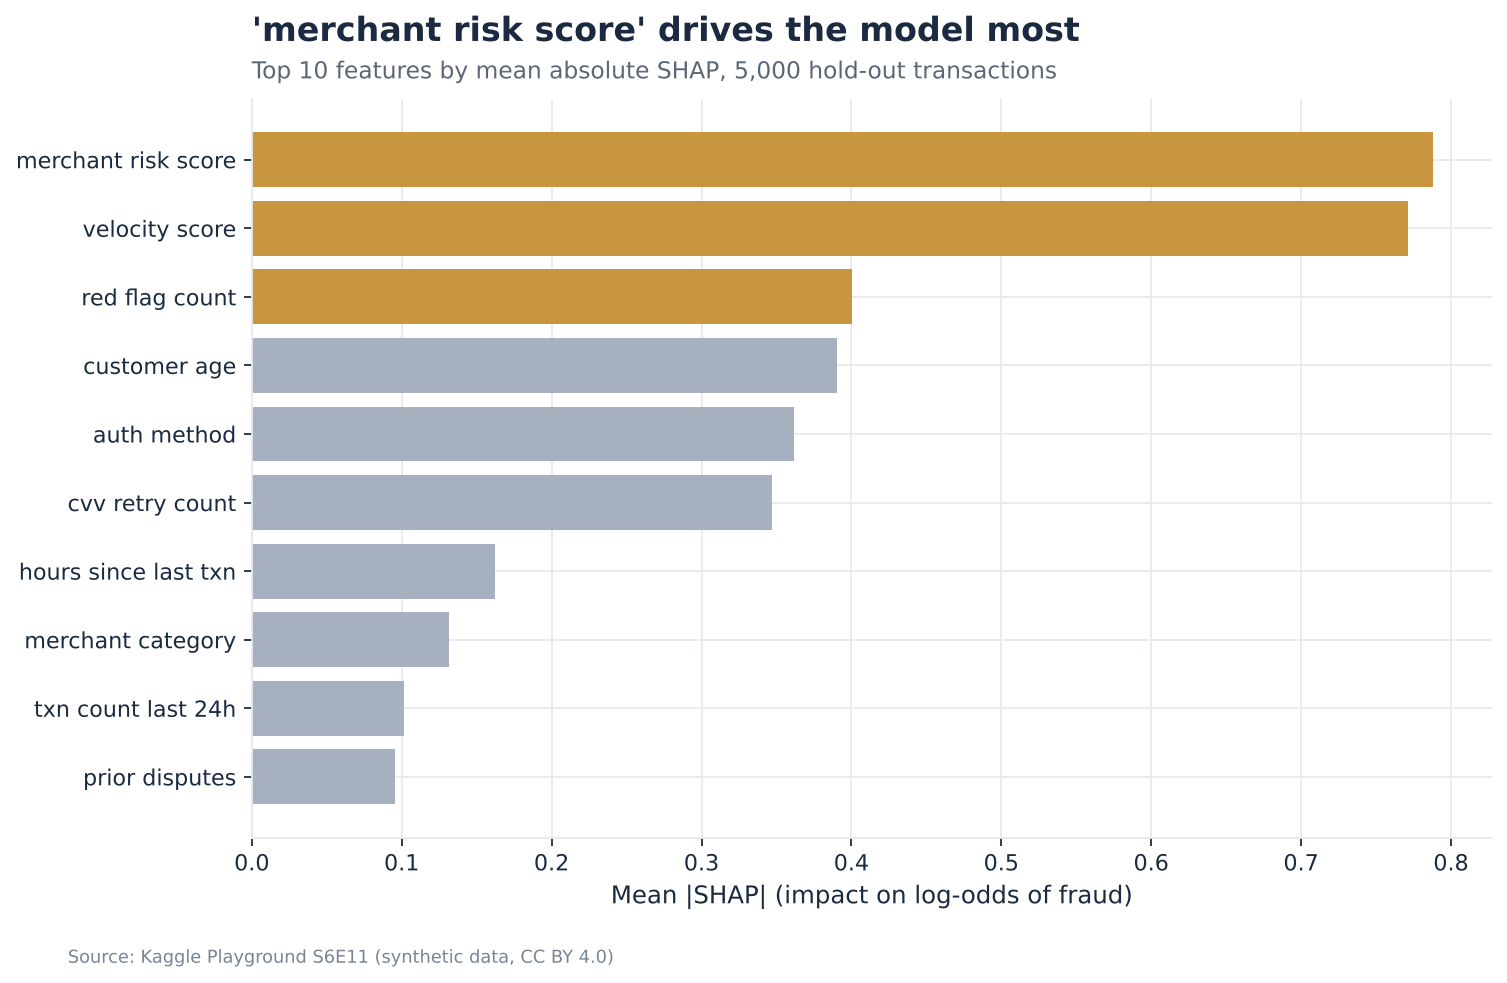

In [16]:
import shap
expl = shap.TreeExplainer(final_lgbm)
sample = hold.sample(5000, random_state=mdl.SEED)
sv = expl.shap_values(mdl.X_tree(sample))
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
METRICS["shap_top10"] = {k: round(float(v), 4) for k, v in imp.head(10).items()}
fig, ax = plt.subplots(figsize=(10, 6))
t10 = imp.head(10).iloc[::-1]
ax.barh([k.replace("_", " ") for k in t10.index], t10.values, color=[style.ACCENT if i >= 7 else style.MUTED for i in range(10)])
ax.set_xlabel("Mean |SHAP| (impact on log-odds of fraud)")
style.title(ax, f"'{imp.index[0].replace('_', ' ')}' drives the model most",
            "Top 10 features by mean absolute SHAP, 5,000 hold-out transactions")
style.source(fig, SRC); style.save(fig, R("figures", "08_shap.png")); Image(R("figures", "08_shap.png"), width=760)

In [17]:
hh = hold.assign(p=p_lgbm)
thr = np.quantile(p_lgbm, 0.99)          # the "review the riskiest 1%" threshold
caught = hh[(hh[TARGET] == 1) & (hh.p >= thr)].sort_values("p", ascending=False)
missed = hh[(hh[TARGET] == 1) & (hh.p < thr)].sort_values("p")
false_alarm = hh[(hh[TARGET] == 0) & (hh.p >= thr)].sort_values("p", ascending=False)
picks = [("caught_fraud", caught.iloc[len(caught) // 2]), ("missed_fraud", missed.iloc[len(missed) // 2]),
         ("false_alarm", false_alarm.iloc[len(false_alarm) // 2])]
cases = []
for label, r in picks:
    s = expl.shap_values(mdl.X_tree(hh.loc[[r.name]]))
    s = (s[1] if isinstance(s, list) else s)[0]
    top = pd.Series(s, index=FEATURES).sort_values(key=np.abs, ascending=False).head(3)
    cases.append({"case": label, "id": int(r[ID]), "predicted_prob_pct": round(float(r.p * 100), 2),
                  "actual": int(r[TARGET]), "amount_usd": float(r.amount_usd), "merchant_category": str(r.merchant_category),
                  "auth_method": str(r.auth_method), "red_flags": int(r.red_flag_count),
                  "merchant_risk_score": float(r.merchant_risk_score),
                  "top_shap": [f"{k} ({'+' if v > 0 else '-'})" for k, v in top.items()]})
METRICS["review_threshold_prob_pct"] = round(float(thr * 100), 3)
METRICS["case_studies"] = cases
pd.DataFrame(cases).T

,0,1,2
case,caught_fraud,missed_fraud,false_alarm
id,484297,616974,253528
predicted_prob_pct,74.13,6.06,48.49
actual,1,1,0
amount_usd,49.12,761.98,36.61
merchant_category,Gaming,Crypto Exchange,Gaming
auth_method,No Authentication,Biometric,3D Secure
red_flags,2,2,1
merchant_risk_score,61.3,69.4,65.4
top_shap,"[red_flag_count (+), velocity_score (+), auth_...","[merchant_risk_score (+), red_flag_count (+), ...","[merchant_risk_score (+), velocity_score (+), ..."


## 9. Final model on all training data → Kaggle submission

In [18]:
full_lgbm = mdl.fit_lgbm(mdl.X_tree(d), d[TARGET], learning_rate=0.05, n_estimators=n_iter, **best)
pt_lgbm = full_lgbm.predict_proba(mdl.X_tree(te))[:, 1]
if chosen.startswith("Blend"):
    full_lr = mdl.make_logreg().fit(d[FEATURES], d[TARGET])
    pt_lr = full_lr.predict_proba(te[FEATURES])[:, 1]
    pred = (rankdata(pt_lgbm) + rankdata(pt_lr)) / (2 * len(pt_lgbm))
else:
    pred = pt_lgbm
sub = pd.DataFrame({ID: te_raw[ID], TARGET: pred})
out_sub = "/kaggle/working/submission.csv" if ON_KAGGLE else R("results", "submission.csv")
sub.to_csv(out_sub, index=False)
METRICS["submission"] = {"rows": int(len(sub)), "n_estimators": n_iter, "model": chosen}
full_lgbm.booster_.save_model(R("models", "lgbm_full.txt"))
defaults = {c: float(d[c].median()) for c in NUMERIC_RAW}
defaults.update({c: str(d[c].mode()[0]) for c in CATEGORICAL})
ranges = {c: [float(d[c].quantile(0.001)), float(d[c].quantile(0.999))] for c in NUMERIC_RAW}
json.dump({"features": FEATURES, "categorical": CATEGORICAL, "categories": cats, "boolean": BOOLEAN,
           "numeric_raw": NUMERIC_RAW, "defaults": defaults, "ranges": ranges,
           "review_threshold_prob": float(thr), "fraud_rate": float(d[TARGET].mean())}, open(R("models", "model_meta.json"), "w"), indent=1)
hh[[ID, TARGET, "p", "amount_usd", "merchant_category", "auth_method", "channel", "red_flag_count",
    "merchant_risk_score", "velocity_score", "cvv_retry_count"]].round(5).to_csv(R("results", "holdout_predictions.csv.gz"), index=False)
sub.head()

,id,is_fraud
0,699960,0.000232
1,699961,0.000129
2,699962,0.072480
3,699963,0.001425
4,699964,0.001183


In [19]:
METRICS["config"] = {"holdout_frac_pct": 20, "n_folds": 5, "optuna_trials": N_TRIALS, "top_review_pct": 1,
                     "rf_subsample_rows": 200000, "shap_sample_rows": 5000, "seed": mdl.SEED, "calibration_bins": 10,
                     "review_grid_pct": [0.5, 1, 2, 5, 10]}
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
json.dump(_clean(METRICS), open(R("results", "metrics.json"), "w", encoding="utf-8"), indent=2, ensure_ascii=False, sort_keys=True)
import make_dashboard
make_dashboard.build(ROOT)
print(json.dumps(METRICS["headline"], indent=1))

{
 "chosen_model": "LightGBM (tuned)",
 "holdout_auc": 0.94601,
 "holdout_pr_auc": 0.52019,
 "holdout_recall_top1pct": 39.17879,
 "holdout_precision_top1pct": 65.42857,
 "rule_holdout_auc": 0.84711,
 "rule_recall_top1pct": 21.21471,
 "one_feature_holdout_auc": 0.74573,
 "cv_auc_chosen": 0.94719,
 "lgbm_holdout_accuracy_at_05": 98.70135,
 "majority_holdout_accuracy": 98.3299,
 "lift_top1pct_x": 39.2,
 "logreg_holdout_auc": 0.94048,
 "lgbm_holdout_auc": 0.94601
}


## Limitations
* **Synthetic data.** Kaggle generated it from another dataset; real fraud is messier and changes over time.
* No time column, so the model cannot be tested on "next month"; in a real bank that test would be required.
* ROC AUC hides the rarity of fraud; PR AUC and the "review 1%" numbers above are the ones a fraud team would feel.
* The decision threshold (review the riskiest 1%) is an example, not a recommendation — it depends on analyst capacity and costs.